<a href="https://colab.research.google.com/github/Lourdes-Churacutipa/Repositorio-de-lourdes/blob/main/Lab8_4_XGBoost_SHAP_Peru.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# XGBoost, Importancia de Características y SHAP
## Ciencia de Datos Ambientales – Aplicado al Perú

**Duración:** 75 minutos

Referencia: [XGBoost](https://xgboost.readthedocs.io/) | [SHAP](https://shap.readthedocs.io/)

---

### Objetivos de aprendizaje

1. Explicar cómo el gradient boosting difiere del bagging (random forests).
2. Entrenar un modelo XGBoost y ajustar sus hiperparámetros clave.
3. Comparar Random Forest y XGBoost en la predicción de radiación solar.
4. Calcular e interpretar tres tipos de importancia: Gini, permutación y SHAP.
5. Leer e interpretar gráficas de resumen SHAP, dependencia y force plots.

## 1. Dos Filosofías de Aprendizaje en Ensemble

### Bagging (Random Forest) — "Consultar a muchos expertos independientes"

Imagina que el SENAMHI quiere estimar la precipitación anual en una cuenca nueva. Consultan a 100 hidrólogos **independientemente** — ninguno sabe lo que dijeron los otros. Luego promedian sus respuestas.

- Entrenar muchos árboles **independientemente** en muestras bootstrap
- Cada árbol es un aprendiz de fuerza completa (árbol profundo)
- Combinar por **voto mayoritario o promedio**
- Meta: **reducir varianza** — suavizar el ruido de los árboles individuales

### Boosting (XGBoost) — "Aprender de los errores"

Un estudiante toma un examen y obtiene 70%. En lugar de empezar de cero, estudia **específicamente las preguntas que erró** y vuelve a rendir. Obtiene 80%, luego estudia los errores restantes y llega a 90%.

- Entrenar árboles **secuencialmente** — cada árbol nuevo se enfoca en los errores del ensemble previo
- Cada árbol es un **aprendiz débil** (árbol poco profundo, típicamente 3-6 de profundidad)
- Combinar por **suma ponderada** — cada árbol agrega una pequeña corrección
- Meta: **reducir sesgo** — corregir iterativamente errores sistemáticos

| | Bagging (Random Forest) | Boosting (XGBoost) |
|---|---|---|
| Entrenamiento de árboles | Independiente, paralelo | Secuencial |
| Profundidad del árbol | Profundo | Poco profundo (3-6) |
| Beneficio principal | Reduce varianza | Reduce sesgo |
| Riesgo de sobreajuste | Bajo | Más alto |

## 2. Cómo Funciona XGBoost

**XGBoost** = e**X**treme **G**radient **Boost**ing. El algoritmo:

**Ronda 0 – Predicción inicial:** Predecir la media para todas las muestras (ej. radiación media = 350 W/m²).

**Ronda 1 – Calcular residuos:** $\text{residuo}_i = y_i - \hat{y}_i^{(0)}$

**Ronda 1 – Ajustar árbol a los residuos:** Entrenar un árbol poco profundo que predice estos residuos.

**Ronda 1 – Actualizar el ensemble:**
$$\hat{y}_i^{(1)} = \hat{y}_i^{(0)} + \eta \cdot \text{árbol}_1(\mathbf{x}_i)$$

donde $\eta$ es la **tasa de aprendizaje** (un paso pequeño para no sobreajustar).

**Rondas 2, 3, ..., $T$:** Continuar hasta que los residuos sean suficientemente pequeños.

### ¿Qué hace a XGBoost "extremo"?
- **Regularización** (L1 y L2) para prevenir sobreajuste
- **Early stopping** — parar cuando el rendimiento de validación deja de mejorar
- **Búsqueda paralela de divisiones** — aunque los árboles son secuenciales, la búsqueda dentro de cada árbol es paralela

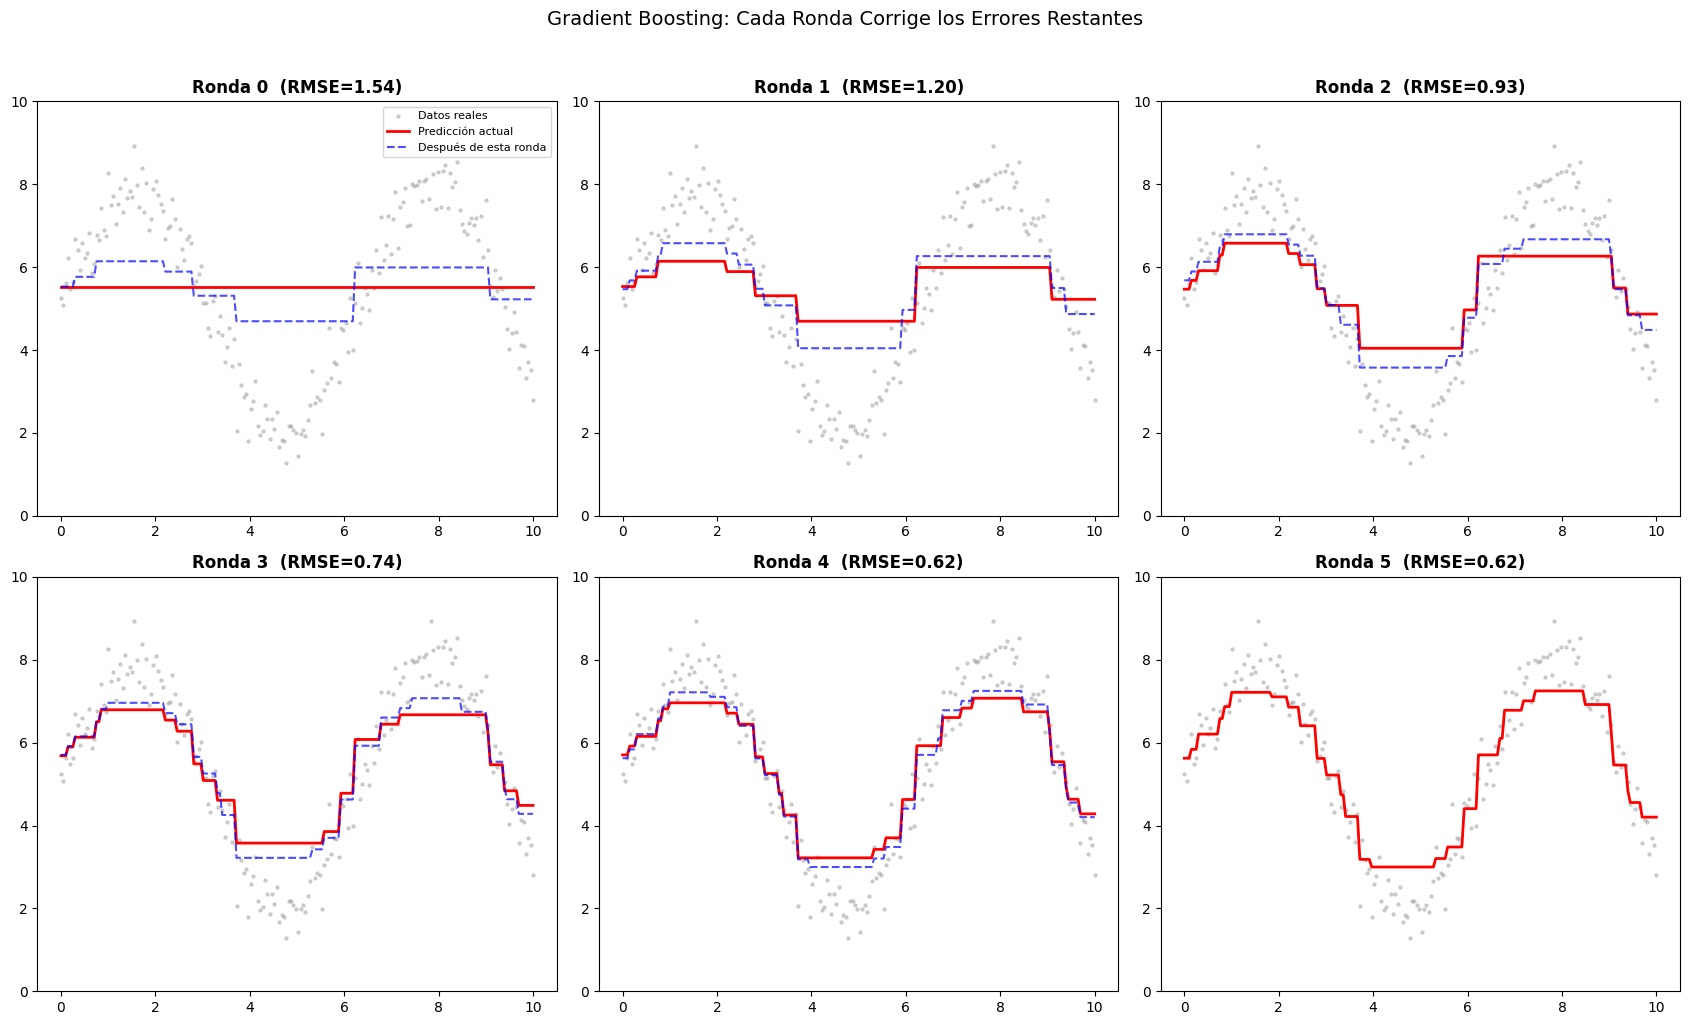

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor

# Visualizar el proceso de boosting conceptualmente
np.random.seed(42)
x = np.linspace(0, 10, 200)
y_verdad = np.sin(x) * 3 + 5
y_ruido  = y_verdad + np.random.normal(0, 0.5, len(x))

fig, ejes = plt.subplots(2, 3, figsize=(17, 10))

prediccion = np.full_like(x, y_ruido.mean())  # Ronda 0: predicción = media
eta = 0.3

for num_ronda, ax in enumerate(ejes.flat):
    residuos = y_ruido - prediccion

    ax.scatter(x, y_ruido, s=5, alpha=0.3, color='gray', label='Datos reales')
    ax.plot(x, prediccion, 'r-', linewidth=2, label='Predicción actual')

    if num_ronda < 5:
        arbol = DecisionTreeRegressor(max_depth=3).fit(x.reshape(-1, 1), residuos)
        correccion = arbol.predict(x.reshape(-1, 1))
        ax.plot(x, prediccion + eta * correccion, 'b--', linewidth=1.5,
                alpha=0.7, label='Después de esta ronda')
        prediccion = prediccion + eta * correccion

    rmse = np.sqrt(np.mean((y_ruido - prediccion)**2))
    ax.set_title(f'Ronda {num_ronda}  (RMSE={rmse:.2f})', fontweight='bold')
    ax.set_ylim(0, 10)
    if num_ronda == 0:
        ax.legend(fontsize=8, loc='upper right')

plt.suptitle('Gradient Boosting: Cada Ronda Corrige los Errores Restantes',
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 3. XGBoost en Python: Predicción de Radiación Solar

In [ ]:
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import time

# Recrear dataset de radiación solar
np.random.seed(42)
n = 5000
ACZ = np.random.uniform(0, 85, n)
AOD = np.random.exponential(0.15, n)
FNC = np.random.uniform(0, 1, n)
VPR = np.random.uniform(0.5, 5, n)
ALB = np.random.uniform(0.05, 0.4, n)
Pre = np.random.uniform(600, 1010, n)

cos_ACZ = np.cos(np.radians(ACZ))
SW_dir  = np.maximum(0, 1361 * cos_ACZ * np.exp(-AOD / np.clip(cos_ACZ, 0.05, 1))
                      * (1 - FNC * 0.9) + np.random.normal(0, 15, n))
SW_dif  = np.maximum(0, 200 * cos_ACZ * (0.3 + 0.5*FNC + 0.3*AOD)
                      + np.random.normal(0, 10, n))
SW_total = SW_dir + SW_dif

X_SW = np.column_stack([ACZ, AOD, FNC, VPR, ALB, Pre])
nombres_SW = ['ACZ', 'AOD', 'FNC', 'VPR', 'ALB', 'Presión']
X_tr, X_te, y_tr, y_te = train_test_split(X_SW, SW_total, test_size=0.25, random_state=42)

# Random Forest
t0 = time.time()
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_tr, y_tr)
t_rf = time.time() - t0
r2_rf   = r2_score(y_te, rf.predict(X_te))
rmse_rf = np.sqrt(mean_squared_error(y_te, rf.predict(X_te)))

# XGBoost
t0 = time.time()
xgb_model = xgb.XGBRegressor(
    n_estimators=500, max_depth=6, learning_rate=0.1,
    subsample=0.8, colsample_bytree=0.8,
    reg_lambda=1.0, random_state=42, n_jobs=-1
)
xgb_model.fit(X_tr, y_tr,
              eval_set=[(X_te, y_te)],
              verbose=False)
t_xgb = time.time() - t0
r2_xgb   = r2_score(y_te, xgb_model.predict(X_te))
rmse_xgb = np.sqrt(mean_squared_error(y_te, xgb_model.predict(X_te)))

print(f"{'Modelo':<20}  {'R² prueba':>10}  {'RMSE (W/m²)':>12}  {'Tiempo (s)':>12}")
print("-" * 57)
print(f"{'Random Forest':<20}  {r2_rf:>10.4f}  {rmse_rf:>12.1f}  {t_rf:>11.2f}")
print(f"{'XGBoost':<20}  {r2_xgb:>10.4f}  {rmse_xgb:>12.1f}  {t_xgb:>11.2f}")

Modelo                 R² prueba   RMSE (W/m²)    Tiempo (s)
---------------------------------------------------------
Random Forest             0.9940          25.1         4.25
XGBoost                   0.9916          29.7         2.55


## 4. Tres Métodos de Importancia de Características

### Método 1: Importancia Gini (MDI)
**Cómo funciona:** Suma la reducción total de impureza de todas las divisiones que usan esa característica.

**Debilidades:** Sesgado hacia características de alta cardinalidad.

### Método 2: Importancia por Permutación
**Cómo funciona:** Mezcla aleatoriamente una característica a la vez y mide cuánto cae el R² del modelo.

**Fortalezas:** Mide importancia para la generalización (en el conjunto de prueba).

### Método 3: SHAP (SHapley Additive exPlanations)
**Cómo funciona:** Para cada predicción individual, descompone la diferencia respecto a la predicción media en contribuciones de cada característica.

$$\hat{y}_i = \phi_0 + \phi_1^{(i)} + \phi_2^{(i)} + \ldots + \phi_M^{(i)}$$

**El estándar de oro de la interpretabilidad** — proporciona explicaciones por muestra, muestra la dirección del efecto, y maneja interacciones.

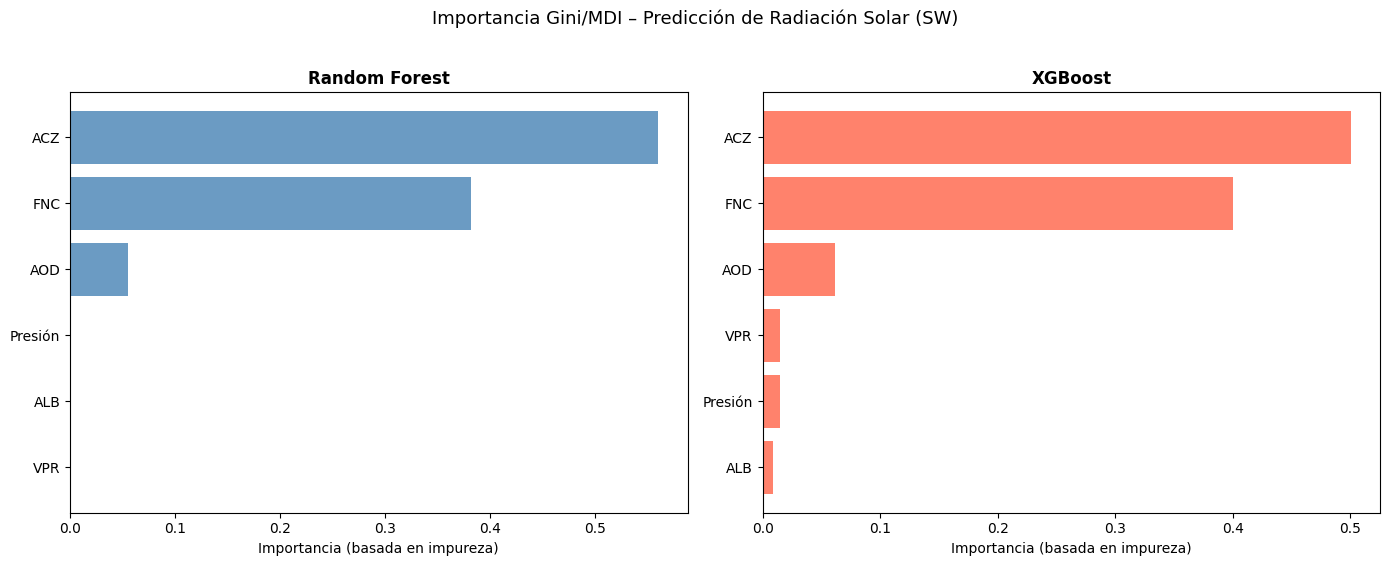

In [ ]:
# Método 1: Importancia Gini
fig, ejes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, imp, nombre, color in zip(ejes,
                                    [rf.feature_importances_, xgb_model.feature_importances_],
                                    ['Random Forest', 'XGBoost'],
                                    ['steelblue', 'tomato']):
    idx_ord = np.argsort(imp)
    ax.barh(range(len(idx_ord)), imp[idx_ord], color=color, alpha=0.8)
    ax.set_yticks(range(len(idx_ord)))
    ax.set_yticklabels(np.array(nombres_SW)[idx_ord])
    ax.set_xlabel('Importancia (basada en impureza)')
    ax.set_title(nombre, fontweight='bold', fontsize=12)

plt.suptitle('Importancia Gini/MDI – Predicción de Radiación Solar (SW)', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

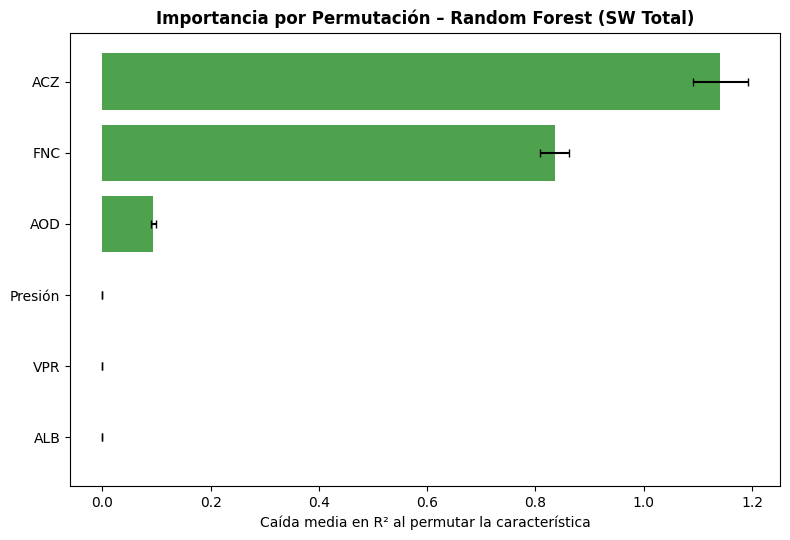

Importancia por permutación (caída en R²):
  ACZ         : 1.1413 ± 0.0508
  FNC         : 0.8354 ± 0.0262
  AOD         : 0.0939 ± 0.0044
  Presión     : 0.0000 ± 0.0000
  VPR         : -0.0000 ± 0.0000
  ALB         : -0.0000 ± 0.0000


In [ ]:
# Método 2: Importancia por Permutación
from sklearn.inspection import permutation_importance

result_perm = permutation_importance(
    rf, X_te, y_te,
    n_repeats=10, random_state=42, n_jobs=-1, scoring='r2'
)

imp_perm = result_perm.importances_mean
std_perm = result_perm.importances_std
idx_ord_perm = np.argsort(imp_perm)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(range(len(idx_ord_perm)), imp_perm[idx_ord_perm], color='forestgreen', alpha=0.8,
        xerr=std_perm[idx_ord_perm], capsize=3)
ax.set_yticks(range(len(idx_ord_perm)))
ax.set_yticklabels(np.array(nombres_SW)[idx_ord_perm])
ax.set_xlabel('Caída media en R² al permutar la característica')
ax.set_title('Importancia por Permutación – Random Forest (SW Total)', fontweight='bold')
plt.tight_layout()
plt.show()

print("Importancia por permutación (caída en R²):")
for idx in np.argsort(imp_perm)[::-1]:
    print(f"  {nombres_SW[idx]:12}: {imp_perm[idx]:.4f} ± {std_perm[idx]:.4f}")

## 5. SHAP: El Estándar de Oro de la Interpretabilidad

In [ ]:
# !pip install shap -q
import shap

# Calcular valores SHAP para XGBoost (TreeExplainer es rápido para árboles)
explicador = shap.TreeExplainer(xgb_model)
valores_shap = explicador.shap_values(X_te)

print(f"Forma de valores SHAP: {valores_shap.shape}")
print(f"  = ({valores_shap.shape[0]} muestras de prueba, {valores_shap.shape[1]} características)")

# Verificar la propiedad aditiva
pred_ejemplo = xgb_model.predict(X_te[:1])[0]
baseline     = explicador.expected_value
suma_shap    = valores_shap[0].sum()

print(f"\nVerificación para la primera muestra de prueba:")
print(f"  Baseline (predicción media): {baseline:.1f} W/m²")
print(f"  Predicción del modelo:       {pred_ejemplo:.1f} W/m²")
print(f"  Suma de valores SHAP:        {suma_shap:.1f}")
print(f"  Baseline + suma SHAP:        {baseline + suma_shap:.1f} W/m²")
print("  (Deben coincidir — la descomposición SHAP es exacta)")

Forma de valores SHAP: (1250, 6)
  = (1250 muestras de prueba, 6 características)

Verificación para la primera muestra de prueba:
  Baseline (predicción media): 494.1 W/m²
  Predicción del modelo:       347.0 W/m²
  Suma de valores SHAP:        -147.1
  Baseline + suma SHAP:        347.0 W/m²
  (Deben coincidir — la descomposición SHAP es exacta)


/tmp/ipykernel_1840/3312987891.py:5: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(valores_shap, X_te_df, show=False, plot_size=None)


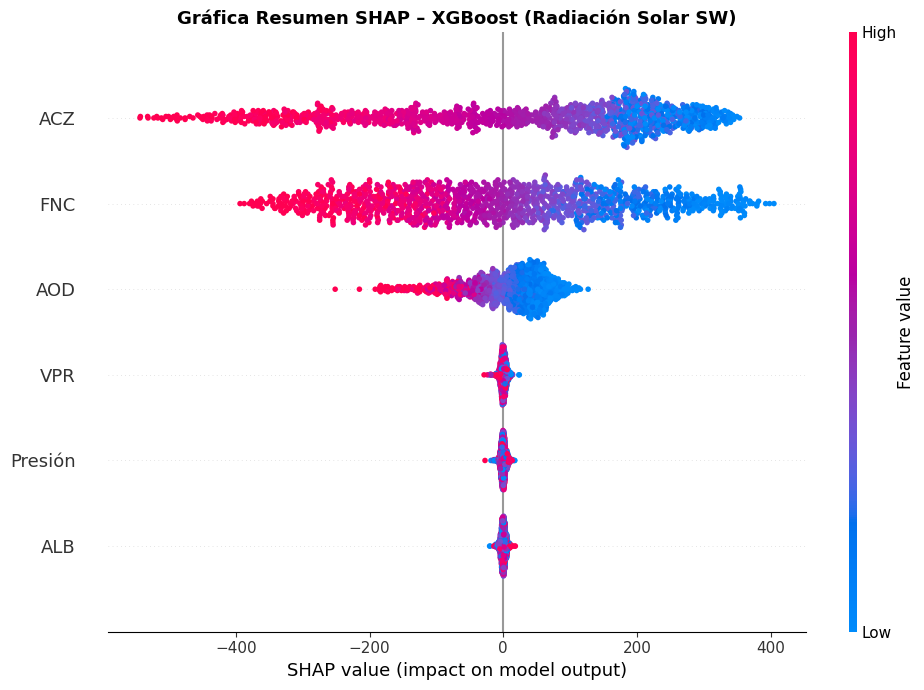

In [ ]:
# Gráfica de Resumen SHAP (Beeswarm)
X_te_df = pd.DataFrame(X_te, columns=nombres_SW)

fig, ax = plt.subplots(figsize=(10, 7))
shap.summary_plot(valores_shap, X_te_df, show=False, plot_size=None)
plt.title('Gráfica Resumen SHAP – XGBoost (Radiación Solar SW)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### Cómo leer la gráfica beeswarm SHAP

- **Cada punto** es una muestra de prueba
- **Posición horizontal** = valor SHAP: izquierda = empuja predicción hacia abajo; derecha = hacia arriba
- **Color** = valor real de la característica (rojo = alto, azul = bajo)
- **Características ordenadas** por importancia global (mayor arriba)

**ACZ (Ángulo Cenital Solar):**
- Puntos rojos (ACZ alto = sol bajo en el horizonte) → lado izquierdo → **disminuye** SW
- Puntos azules (ACZ bajo = sol alto) → lado derecho → **aumenta** SW
- Esto es físicamente correcto: cuanto más alto el sol, más radiación llega a la superficie

**FNC (Fracción de Nubosidad):**
- Puntos rojos (alta nubosidad) → lado izquierdo → **disminuye** SW
- Las nubes bloquean la radiación solar

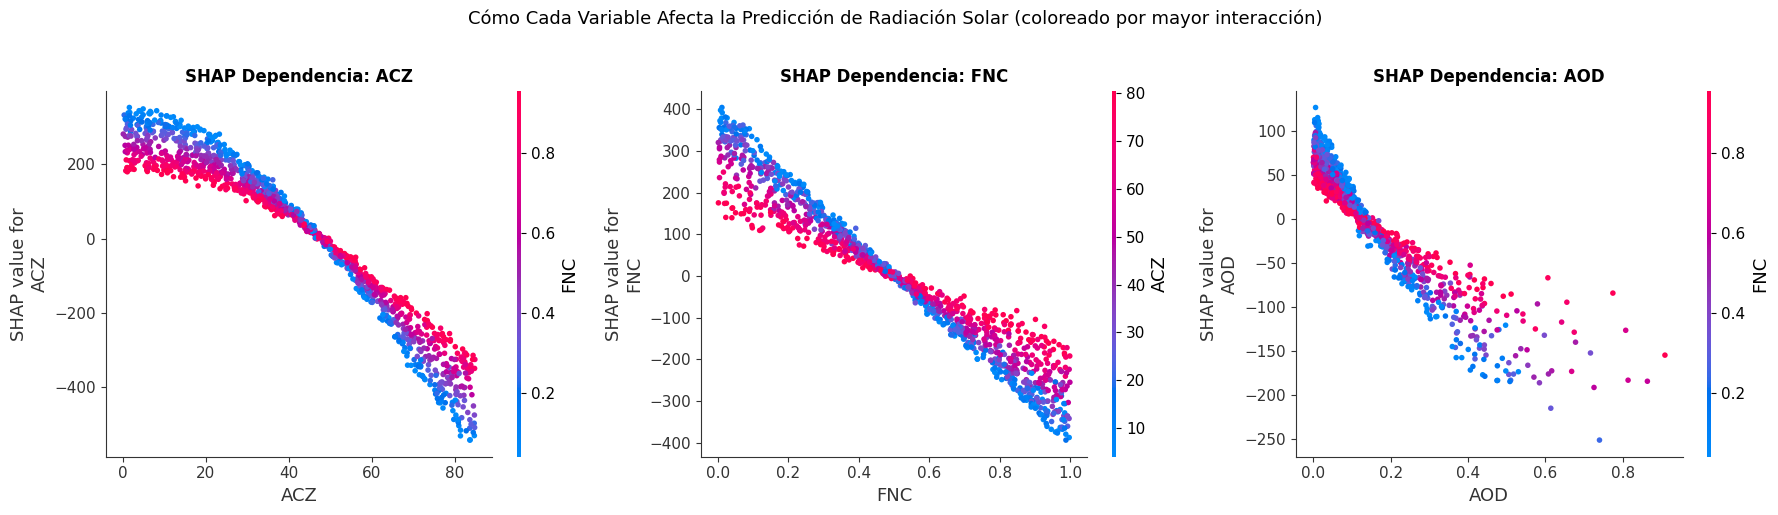

Interpretación de las gráficas de dependencia:

  ACZ: Relación no lineal fuerte — la radiación cae rápidamente cuando ACZ > 60°
       (coseno del ángulo solar — Ley de Lambert)

  FNC: Relación negativa — más nubes → menos radiación directa
       Alta dispersión indica interacción con AOD y ACZ

  AOD: Efecto negativo — más aerosoles atenúan el haz solar
       El efecto es mayor cuando ACZ es bajo (sol alto, mayor camino en atmósfera)


In [ ]:
# Gráficas de Dependencia SHAP para las 3 variables más importantes
fig, ejes = plt.subplots(1, 3, figsize=(18, 5))

for ax, caracteristica in zip(ejes, ['ACZ', 'FNC', 'AOD']):
    shap.dependence_plot(caracteristica, valores_shap, X_te_df, ax=ax, show=False)
    ax.set_title(f'SHAP Dependencia: {caracteristica}', fontweight='bold')

plt.suptitle('Cómo Cada Variable Afecta la Predicción de Radiación Solar (coloreado por mayor interacción)',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print("Interpretación de las gráficas de dependencia:")
print("\n  ACZ: Relación no lineal fuerte — la radiación cae rápidamente cuando ACZ > 60°")
print("       (coseno del ángulo solar — Ley de Lambert)")
print("\n  FNC: Relación negativa — más nubes → menos radiación directa")
print("       Alta dispersión indica interacción con AOD y ACZ")
print("\n  AOD: Efecto negativo — más aerosoles atenúan el haz solar")
print("       El efecto es mayor cuando ACZ es bajo (sol alto, mayor camino en atmósfera)")

---
## 🔬 Ejercicio: Comparación Gran Final de Modelos

Comparar **todos los algoritmos** del curso en la predicción de radiación solar total:

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler

esc = StandardScaler()
X_tr_e = esc.fit_transform(X_tr)
X_te_e = esc.transform(X_te)

regresores = [
    ("Regresión Lineal",      LinearRegression(),                                              X_tr_e, X_te_e),
    ("KNN (k=10)",            KNeighborsRegressor(10),                                        X_tr_e, X_te_e),
    ("SVR (RBF)",             SVR(kernel='rbf', C=100),                                       X_tr_e, X_te_e),
    ("Árbol (depth=10)",      DecisionTreeRegressor(max_depth=10, random_state=42),           X_tr, X_te),
    ("Random Forest",         RandomForestRegressor(200, random_state=42, n_jobs=-1),         X_tr, X_te),
    ("XGBoost",               xgb.XGBRegressor(n_estimators=500, max_depth=6, learning_rate=0.1,
                                               random_state=42, n_jobs=-1),                  X_tr, X_te),
]

todos_resultados = []
print(f"{'Modelo':<22}  {'R² prueba':>10}  {'RMSE (W/m²)':>12}  {'Escalado?':>10}")
print("-" * 58)

for nombre, modelo, Xtr, Xte in regresores:
    modelo.fit(Xtr, y_tr)
    r2   = r2_score(y_te, modelo.predict(Xte))
    rmse = np.sqrt(mean_squared_error(y_te, modelo.predict(Xte)))
    esc_str = 'Sí' if nombre in ['Regresión Lineal', 'KNN (k=10)', 'SVR (RBF)'] else 'No'
    todos_resultados.append((nombre, r2, rmse))
    print(f"{nombre:<22}  {r2:>10.4f}  {rmse:>12.1f}  {esc_str:>10}")

print("\n→ Random Forest y XGBoost son los mejores sin necesidad de escalar")

Modelo                   R² prueba   RMSE (W/m²)   Escalado?
----------------------------------------------------------
Regresión Lineal            0.8882         108.0          Sí
KNN (k=10)                  0.9674          58.3          Sí
SVR (RBF)                   0.9949          23.1          Sí
Árbol (depth=10)            0.9830          42.2          No
Random Forest               0.9940          25.1          No
XGBoost                     0.9951          22.7          No

→ Random Forest y XGBoost son los mejores sin necesidad de escalar


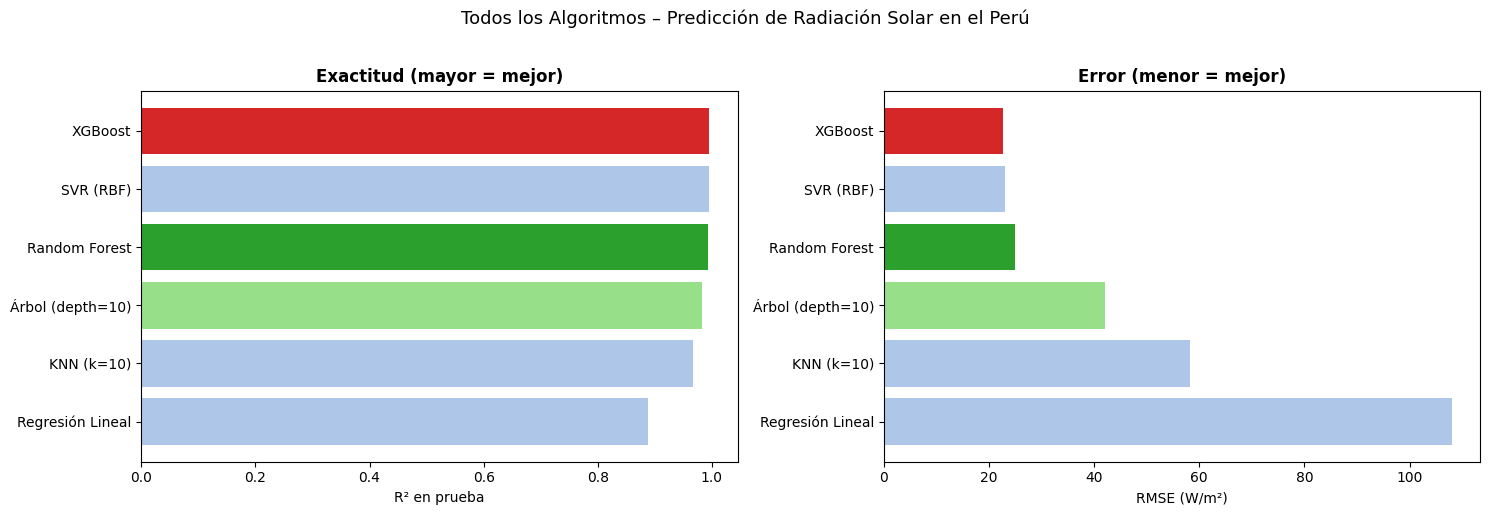

In [ ]:
# Visualizar comparación
nombres_mod = [r[0] for r in todos_resultados]
r2s         = [r[1] for r in todos_resultados]
rmses       = [r[2] for r in todos_resultados]

fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
colores_barras = ['#aec7e8','#aec7e8','#aec7e8','#98df8a','#2ca02c','#d62728']

idx_ord_r2 = np.argsort(r2s)
ejes[0].barh([nombres_mod[i] for i in idx_ord_r2], [r2s[i] for i in idx_ord_r2],
              color=[colores_barras[i] for i in idx_ord_r2])
ejes[0].set_xlabel('R² en prueba')
ejes[0].set_title('Exactitud (mayor = mejor)', fontweight='bold')

idx_ord_rmse = np.argsort(rmses)[::-1]
ejes[1].barh([nombres_mod[i] for i in idx_ord_rmse], [rmses[i] for i in idx_ord_rmse],
              color=[colores_barras[i] for i in idx_ord_rmse])
ejes[1].set_xlabel('RMSE (W/m²)')
ejes[1].set_title('Error (menor = mejor)', fontweight='bold')

plt.suptitle('Todos los Algoritmos – Predicción de Radiación Solar en el Perú', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

---
## 11. Analisis SHAP: Radiacion Directa vs. Difusa

El poder real de SHAP aparece al comparar explicaciones para diferentes variables objetivo.
Entrenemos modelos separados para SW directa y SW difusa y comparemos que variables dominan cada componente.

SW Directa  R2: 0.9960
SW Difusa   R2: 0.9303


/tmp/ipykernel_1840/2898746921.py:38: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  plt.sca(ejes[0]); shap.summary_plot(shap_dir, X_te_df, show=False, plot_size=None)
/tmp/ipykernel_1840/2898746921.py:40: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  plt.sca(ejes[1]); shap.summary_plot(shap_dif, X_te_df, show=False, plot_size=None)


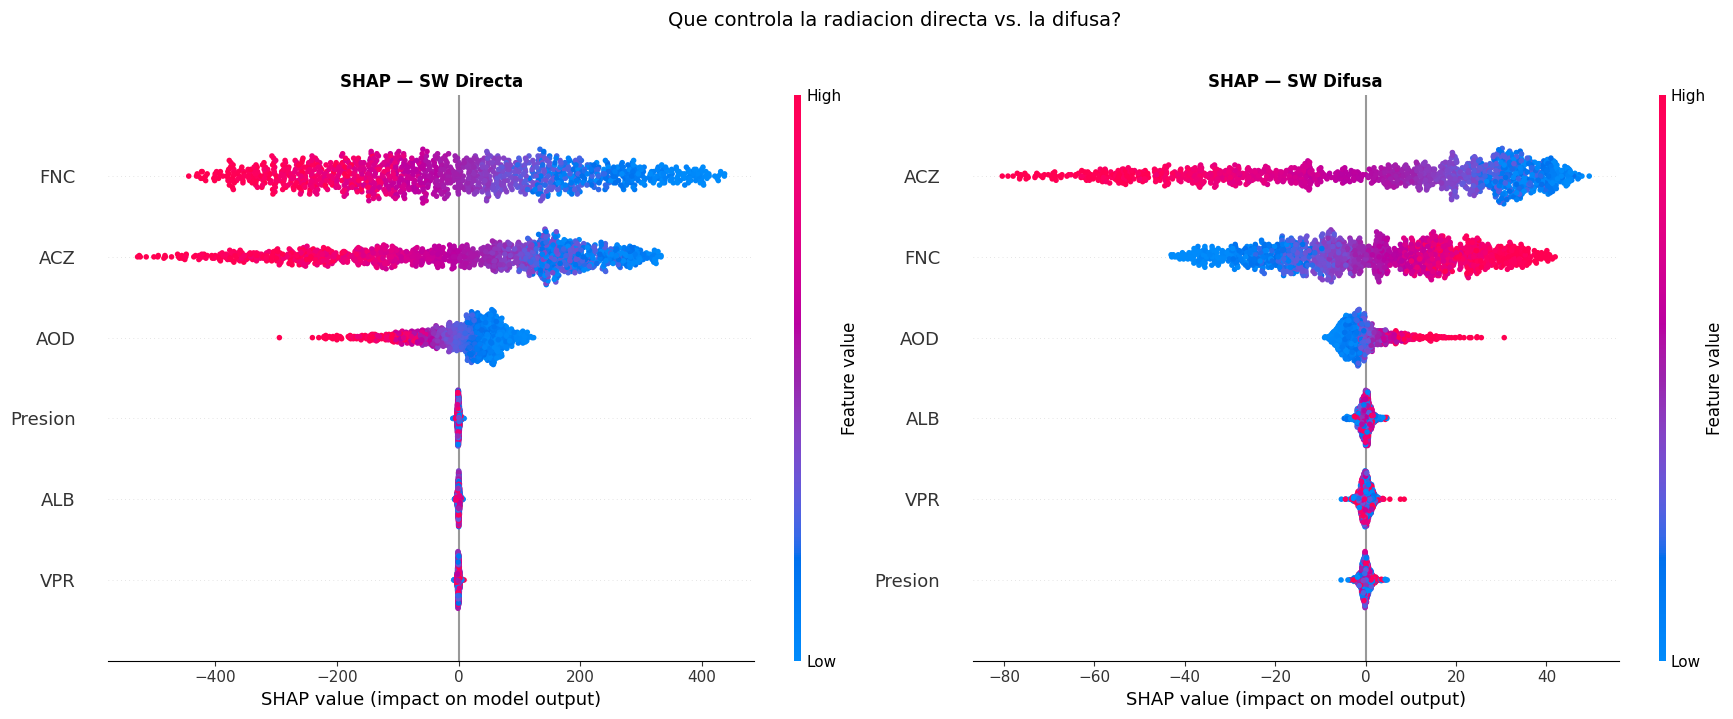

In [ ]:
import xgboost as xgb, shap, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

# Recrear datos de radiacion solar
np.random.seed(42)
n = 5000
ACZ = np.random.uniform(0, 85, n)
AOD = np.random.exponential(0.15, n)
FNC = np.random.uniform(0, 1, n)
VPR = np.random.uniform(0.5, 5, n)
ALB = np.random.uniform(0.05, 0.4, n)
Pre = np.random.uniform(600, 1010, n)

cos_ACZ = np.cos(np.radians(ACZ))
SW_dir = np.maximum(0, 1361*cos_ACZ*np.exp(-AOD/np.clip(cos_ACZ,0.05,1))*(1-FNC*0.9)+np.random.normal(0,15,n))
SW_dif = np.maximum(0, 200*cos_ACZ*(0.3+0.5*FNC+0.3*AOD)+np.random.normal(0,10,n))

X = np.column_stack([ACZ, AOD, FNC, VPR, ALB, Pre])
nombres = ['ACZ','AOD','FNC','VPR','ALB','Presion']
X_tr, X_te, yd_tr, yd_te, yf_tr, yf_te = train_test_split(X, SW_dir, SW_dif, test_size=0.25, random_state=42)

def entrenar(Xtr, ytr, Xte, yte):
    m = xgb.XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1)
    m.fit(Xtr, ytr, eval_set=[(Xte, yte)], verbose=False)
    return m

xgb_dir = entrenar(X_tr, yd_tr, X_te, yd_te)
xgb_dif = entrenar(X_tr, yf_tr, X_te, yf_te)
print(f"SW Directa  R2: {r2_score(yd_te, xgb_dir.predict(X_te)):.4f}")
print(f"SW Difusa   R2: {r2_score(yf_te, xgb_dif.predict(X_te)):.4f}")

shap_dir = shap.TreeExplainer(xgb_dir).shap_values(X_te)
shap_dif = shap.TreeExplainer(xgb_dif).shap_values(X_te)
X_te_df = pd.DataFrame(X_te, columns=nombres)

fig, ejes = plt.subplots(1, 2, figsize=(18, 7))
plt.sca(ejes[0]); shap.summary_plot(shap_dir, X_te_df, show=False, plot_size=None)
ejes[0].set_title('SHAP — SW Directa', fontweight='bold', fontsize=12)
plt.sca(ejes[1]); shap.summary_plot(shap_dif, X_te_df, show=False, plot_size=None)
ejes[1].set_title('SHAP — SW Difusa', fontweight='bold', fontsize=12)
plt.suptitle('Que controla la radiacion directa vs. la difusa?', fontsize=14, y=1.02)
plt.tight_layout(); plt.show()

### Interpretacion fisica

**SW Directa:**
- **ACZ** domina — el coseno del angulo solar determina la intensidad del haz directo (Ley de Lambert)
- **FNC** (nubosidad) tiene efecto fuertemente negativo — las nubes bloquean el haz directo
- **AOD** tiene efecto negativo — los aerosoles atenuan el haz (Ley de Beer-Lambert)

**SW Difusa:**
- **ACZ** sigue siendo importante (controla la energia total disponible)
- **FNC** tiene efecto complejo: nubes moderadas AUMENTAN la difusa (dispersan el haz directo), pero nubes muy densas la reducen
- **AOD** puede tener efecto positivo — los aerosoles tambien dispersan radiacion directa en difusa

> **Relevancia para el Peru:** La costa norte (poca nubosidad) es ideal para concentradores solares.
> La sierra con mas nubes puede aprovechar mejor los paneles fotovoltaicos estaticos.

---
## Resumen

| Concepto | Conclusión clave |
|----------|------------------|
| Bagging (RF) | Árboles independientes en muestras bootstrap; reduce varianza |
| Boosting (XGBoost) | Árboles secuenciales que corrigen residuos; reduce sesgo |
| Tasa de aprendizaje ($\eta$) | Controla el tamaño del paso; pequeña = conservadora, necesita más rondas |
| Early stopping | Para el boosting cuando la pérdida de validación deja de mejorar |
| Importancia Gini | Rápida pero sesgada hacia características de alta cardinalidad |
| Importancia permutación | Agnóstica al modelo; mide caída de exactitud al permutar característica |
| Valores SHAP | Descomposición por muestra; estándar de oro de interpretabilidad |
| Gráfica beeswarm | Muestra importancia, dirección y distribución de valores para cada muestra |
| Gráfica dependencia | Revela efectos no lineales e interacciones entre características |
| Resultado para radiación SW | ACZ domina SW total; FNC y AOD controlan el haz directo; FNC y COD impulsan la difusa |

### Referencia de todos los algoritmos del curso

| Lab | Algoritmo | Mejor para |
|-----|-----------|------------|
| 7_1 | Regresión Lineal / Logística | Línea base simple, interpretabilidad |
| 7_2 | SVM | Datasets pequeños, no-linealidad con kernel |
| 7_3 | Naive Bayes | Línea base rápida, datos de conteo/texto |
| 7_4 | KNN | Problemas no paramétricos simples |
| 8_1 | K-Means | Clustering no supervisado |
| 8_2 | PCA | Reducción de dimensiones, visualización |
| 8_3 | Árboles / Random Forests | Datos tabulares (la opción predeterminada) |
| **8_4** | **XGBoost + SHAP** | **Máxima exactitud + interpretabilidad profunda** |